In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
%pip install kagglehub

import kagglehub

Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_csv("C:\\Users\\NocTo\\OneDrive\\Ambiente de Trabalho\\amz_uk_price_prediction_dataset.csv")

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.shape

(2443651, 9)

In [7]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [8]:
# Retrieving the unique data types present in the dataframe columns
list(set(df.dtypes.tolist()))

[dtype('bool'), dtype('float64'), dtype('O'), dtype('int64')]

In [9]:
# Extracting column names with numerical data types from the dataframe
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [10]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [11]:
# Retrieving column names with object (typically string) data types from the dataframe
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [12]:
# Counting and sorting the unique values for each object (string) column in descending order
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [13]:
# Frequency table for 'category'
frequency_table = df['category'].value_counts()

# Displaying the frequency table
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [14]:
# Top 5 most frequent categories
ft = frequency_table.head()
top5 = df['category'].value_counts().head(5).index

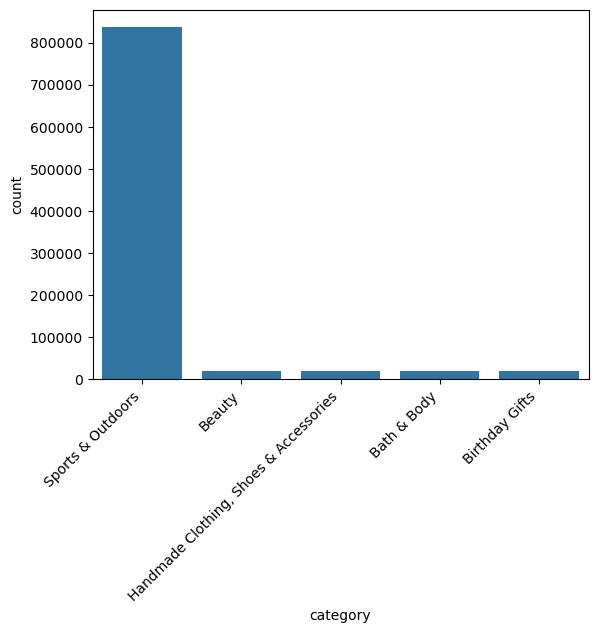

In [15]:
# Using a chart bar, display the distribution of products across different categories
#1
sns.countplot(data=df[df['category'].isin(top5)], x='category', order=top5)

plt.xticks(rotation=45, ha='right')
plt.show()

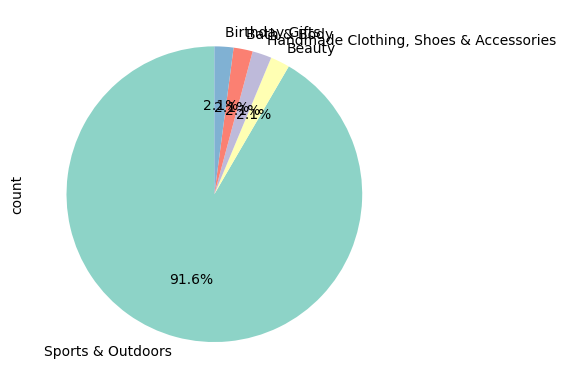

In [19]:
#2
ft.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3")) 
plt.show()

# Sports & Outdoors is the most popular category in this dataset.

In [ ]:
#Part 2
#1 Measures of Centrality
#Average price
df['price'].mean()

np.float64(89.24380943923663)

In [23]:
df['price'].median()

19.09

In [ ]:
#Most common price
df['price'].mode()

0    9.99
Name: price, dtype: float64

In [ ]:
# The average price point of products listed is approximately 89, while the mode is 9.99, indicating that most products are priced lower than the average.

In [25]:
#2 Measures of Dispersion:
df['price'].var()

119445.48532256528

In [ ]:
# Standard Deviation
df['price'].std()

345.60886175352226

In [ ]:
# Range
df['price'].max() - df['price'].min()

100000.0

In [29]:
# Interquartile Range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
IQR

np.float64(36.0)

In [ ]:
# How varied are the product prices? Are there any indicators of a significant spread in prices?
# The standard deviation of 345.6 and a range of 100000 indicate a significant spread in product prices, which suggests a high variability in pricing across the dataset.

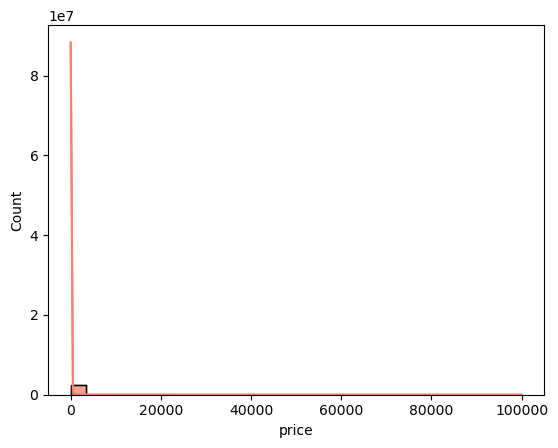

In [34]:
#3
# Histogram to visualize the distribution of product prices
sns.histplot(df['price'], kde=True, bins=30, color="salmon")
plt.show()



In [ ]:
# This histogram is messy because of outliers with very high prices skewing the distribution. To solve this issue we could limit the x-axis to a certain range or remove outliers from the dataset.

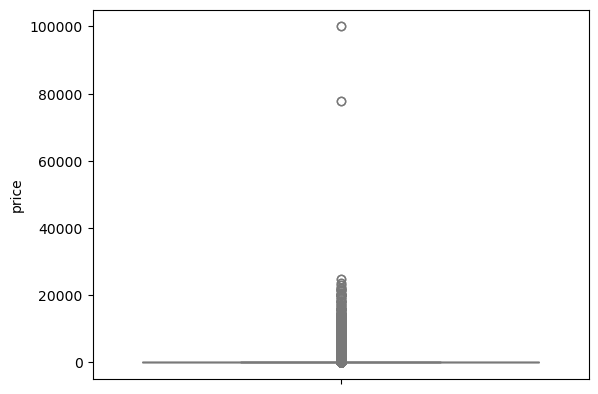

In [36]:
# Box plot to showcase the spread and potential outliers in product pricing
sns.boxplot(data = df['price'], color="lightblue")
plt.show()

In [42]:
#Part 3
df['stars'].mean()

np.float64(2.152836472966065)

In [45]:
df['stars'].median()

0.0

In [46]:
df['stars'].mode()

0    0.0
Name: stars, dtype: float64

In [ ]:
# Customers tend to not leave star ratings but based on the average when they do, they rate around 2 stars.

In [47]:
df['stars'].var()

4.81743402976196

In [48]:
df['stars'].std()

2.1948653785054697

In [49]:
# Interquartile Range (IQR)
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR = Q3 - Q1
IQR

np.float64(4.4)

In [ ]:
# The stars given by 

In [50]:
#3
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()

skewness_stars, kurtosis_stars

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

In [ ]:
#  The normal value of skewness (0.08) for the 'stars' indicates that the distribution is perfectly distributed. This means that the boths tails (higher ratings and lower ratings) are equal. In practical terms, this suggests that stars are rated consistently across the board, with no significant bias towards higher or lower ratings.
# The kurtosis value of -1.9 indicates a low kurtosis, suggesting that the distribution of 'stars' has lighter tails and a flatter peak compared to a normal distribution. This implies fewer extreme values (outliers) in the star ratings, indicating that most ratings cluster around the mean without significant deviations.

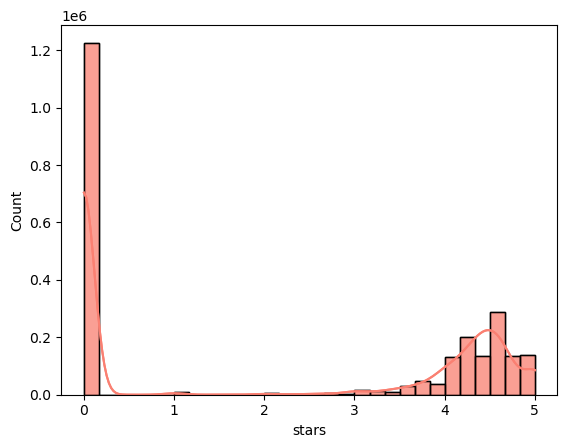

In [52]:
#4
sns.histplot(df['stars'], kde=True, bins=30, color="salmon")
plt.show()


In [ ]:
#0 is the most common star rating given by customers.